# PIQBIT — Détecteur de CV : de la donnée brute au modèle en production

Ce notebook rejoue **toute la chaîne du détecteur de CV** et la met en perspective :

| § | Étape |
|---|---|
| 1 | Extraction du texte et construction du dataset |
| 2 | Nettoyage et masquage |
| 3 | Découpage 80 / 20 stratifié (classe × langue) |
| 4 | Vectorisation TF-IDF (mots et paires de mots) |
| 5 | Pondération classe × langue et augmentation par extraits courts |
| 6 | **Classification** : comparaison de 7 algorithmes (régression logistique, Naive Bayes, SVM, k-NN, arbre de décision, forêt aléatoire, XGBoost) |
| 7 | Résultats détaillés de **XGBoost** (courbe d'apprentissage, importance des termes) |
| 8 | **Arbre de décision** visualisé |
| 9 | **Clustering K-Means** (non supervisé) |
| 10 | **Régression** : prédiction du salaire (autre modèle de PIQBIT) |
| 11 | Choix du meilleur classifieur et évaluation sur le jeu de test |
| 12 | Seuils de décision et tests de résistance |
| 13 | Démonstration : refus d'un document non-CV au dépôt |
| 14 | Application du meilleur modèle (sauvegarde) |

**Règles suivies** — identiques à `train.py` :
* le jeu de test (20 %) n'est **jamais** utilisé pour choisir un modèle : la comparaison se fait par validation croisée sur l'entraînement seul ;
* le vocabulaire TF-IDF est appris dans chaque pli, sur les documents d'entraînement de ce pli uniquement ;
* aucun texte ni nom de fichier de CV n'est affiché : seulement des totaux, des probabilités et des termes du vocabulaire.

**Prérequis** (une fois, dans le venv du backend) :
```
venv\Scripts\pip install ipykernel matplotlib xgboost
```
Puis choisir le noyau `venv` du backend pour exécuter les cellules dans l'ordre.

In [11]:
# Installe les bibliothèques de visualisation et XGBoost si elles manquent.
%pip install joblib matplotlib numpy pandas scikit-learn xgboost
%pip install "pydantic>=2,<3" pydantic-settings
%pip install fastapi "pydantic>=2,<3" pydantic-settings sqlalchemy asyncpg alembic python-dotenv
%pip install -r "E:/PIQBIT/backend/requirements.txt"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached starlette-1.7.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 1.2 MB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 1.3 MB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 1.3 MB/s eta 0:00:02
   --------------------- ------------------ 1.3/2.4 MB 1.2 MB/s eta 0:00:01
   ------------------------- -------------- 1.6/2.4 MB 1.2 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 1.2 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 1.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/626.8 kB

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached aiosqlite-0.22.1-py3-none-any.whl.metadata (4.3 kB)
  Using cached alembic-1.18.4-py3-none-any.whl.metadata (7.2 kB)
  Using cached annotated_doc-0.0.4-py3-none-any.whl.metadata (6.6 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
  Using cached bcrypt-5.0.0-cp39-abi3-win_amd64.whl.metadata (10 kB)
  Using cached cachetools-5.5.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached certifi-2026.4.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached click-8.4.2-py3-none-any.whl.metadata (2.6 kB)
  Using cached cryptography-49.0.0-cp311-abi3-win_amd64.whl.metadata (4.3 kB)
  Using cached dnspython-2.8.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached ecdsa-0.19.2-py2.py3-none-any.whl.metadata (29 kB)
  Using cached email_validator-2.3.0-py3-none-any.whl.metadata (26 kB)
  Using cached fastapi-0.136.1-py3-none-any.whl.metadata (28 kB)
  Using cached filelock-3.29.7-py3-none-any.whl.metadata (2.0 kB)
  Using cached fsspec-2026.6.0-py3-none-any.whl.m

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location

## 0. Préparation

In [12]:
%matplotlib inline
import json
import logging
import os
import sys
import time
import warnings
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path
from xml.sax.saxutils import escape

# Le notebook peut être ouvert depuis backend/ ou backend/cv_detector/.
BACKEND = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "app").is_dir() and (p / "cv_detector").is_dir())
os.chdir(BACKEND)                       # les réglages (.env) se lisent depuis backend/
for chemin in (BACKEND, BACKEND / "cv_detector"):
    if str(chemin) not in sys.path:
        sys.path.insert(0, str(chemin))
logging.disable(logging.INFO)
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, adjusted_rand_score, confusion_matrix, f1_score,
                             homogeneity_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import (GroupKFold, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

import train                                            # la chaîne de production (fonctions réutilisées)
from build_dataset import construire
from app.core.config import settings
from app.services.cv_detection import DetecteurCV, nettoyer_texte
from app.services.cv_parser import cv_parser

try:
    from xgboost import XGBClassifier, XGBRegressor
    XGB = True
except ImportError:
    XGB = False
    print("XGBoost absent : exécutez la cellule d'installation, puis relancez le noyau.")

GRAINE = train.GRAINE
COLONNE = train.COLONNE
SEUIL_REFUS = settings.CV_DETECTOR_REJECT_THRESHOLD
SEUIL_ACCEPTE = settings.CV_DETECTOR_ACCEPT_THRESHOLD
DOSSIER_MODELES = BACKEND / "cv_detector" / "models"

C_CV, C_NON, C_ENCRE = "#23985A", "#E5484D", "#0F2440"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
print(f"backend : {BACKEND}\nseuils : refus < {SEUIL_REFUS}, accepté ≥ {SEUIL_ACCEPTE}\nXGBoost : {XGB}")

backend : e:\PIQBIT\backend
seuils : refus < 0.5, accepté ≥ 0.8
XGBoost : True


## 1. Extraction du texte et construction du dataset

`construire()` lit `cv_detector/dataset/` (CV en PDF / DOCX, non-CV en TXT et offres de la
plateforme), extrait le texte **avec l'extracteur de production** (`cv_parser`), le nettoie, écarte
les doublons et les documents illisibles, puis écrit `dataset.csv`.

> Pour ajouter des CV : déposer les fichiers dans `dataset/cv/francais/` ou `dataset/cv/anglais/`,
> puis réexécuter le notebook depuis cette cellule.

In [14]:
construire(verbeux=True)
df = pd.read_csv(BACKEND / "cv_detector" / "dataset.csv", encoding="utf-8-sig")
df["texte"] = df["texte"].fillna("")
df[COLONNE] = df[COLONNE].fillna("")
pd.crosstab(df["label"], df["langue"], margins=True, margins_name="total")

Error extracting PDF text: 
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats
Could not get FontBBox from font descriptor because None cannot be parsed as 4 floats



dataset.csv : 242 documents -> E:\PIQBIT\backend\cv_detector\dataset.csv

              en    fr   total
CV            36    74     110
NOT_CV        60    72     132

Longueur du texte extrait (caractères, médiane) :
  CV           3902   (min 1131, max 17702)
  NOT_CV        746   (min 154, max 3225)

Catégories NOT_CV : Attestation 20, Certificat 20, Diplôme 20, Lettre de motivation 20, Offre d'emploi 12, Rapport 20, Relevé de notes 20

Écartés, texte illisible (< 150 caractères) : CV_FR_005
Écartés, doublons : CV_FR_039 = CV_FR_012, CV_FR_041 = CV_FR_040, CV_FR_050 = CV_FR_049, CV_FR_058 = CV_FR_057, CV_FR_061 = CV_FR_060, CV_FR_069 = CV_FR_063, CV_FR_070 = CV_FR_064, CV_FR_074 = CV_FR_062, CV_FR_084 = CV_FR_083, NOT_CV_FR_063 = NOT_CV_FR_061, NOT_CV_FR_064 = NOT_CV_FR_062, NOT_CV_FR_066 = NOT_CV_FR_062, NOT_CV_FR_067 = NOT_CV_FR_062, NOT_CV_FR_068 = NOT_CV_FR_061, NOT_CV_FR_069 = NOT_CV_FR_061
Artefacts de collecte neutralisés dans : 36 CV, 113 NOT_CV


langue,en,fr,total
label,,,
CV,36,74,110
NOT_CV,60,72,132
total,96,146,242


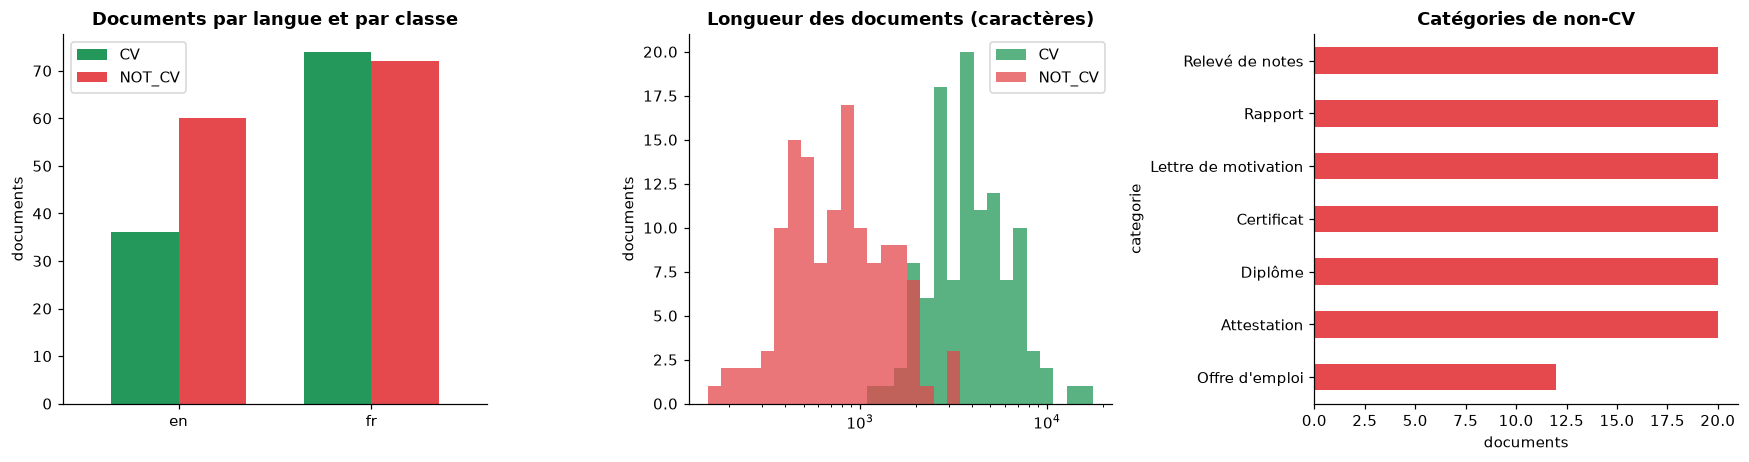

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

pd.crosstab(df["langue"], df["label"]).plot.bar(ax=axes[0], color=[C_CV, C_NON], rot=0, width=.7)
axes[0].set_title("Documents par langue et par classe")
axes[0].set_xlabel(""); axes[0].set_ylabel("documents"); axes[0].legend(title="")

bornes = np.logspace(np.log10(max(df["nb_caracteres"].min(), 10)), np.log10(df["nb_caracteres"].max()), 30)
for label, couleur in (("CV", C_CV), ("NOT_CV", C_NON)):
    axes[1].hist(df.loc[df["label"] == label, "nb_caracteres"], bins=bornes, alpha=.75, color=couleur, label=label)
axes[1].set_xscale("log"); axes[1].legend()
axes[1].set_title("Longueur des documents (caractères)"); axes[1].set_ylabel("documents")

df.loc[df["label"] == "NOT_CV", "categorie"].value_counts().sort_values().plot.barh(ax=axes[2], color=C_NON)
axes[2].set_title("Catégories de non-CV"); axes[2].set_xlabel("documents")
plt.tight_layout(); plt.show()

**À retenir** — le graphe des longueurs montre le biais principal du dataset : les documents courts
sont presque tous des non-CV. Sans correction, un modèle apprend « court = pas un CV »
(corrigé au § 5 par l'augmentation).

## 2. Nettoyage et masquage

`nettoyer_texte` (le `preprocessor` du vectoriseur, donc appliqué à l'identique en production) :
recolle les mots coupés en fin de ligne, recompose les lettres espacées, **masque** les e-mails,
URL, années et numéros de téléphone par un jeton, met en minuscules et normalise les espaces.

Démonstration sur un texte **fictif** :

In [16]:
exemple = (
    "Expérience professionnelle 2019 - 2023\n"
    "Contact : prenom.nom@exemple.com | +216 20 123 456\n"
    "Portfolio : https://exemple.dev/projets\n"
    "C o m p é t e n c e s : Python, SQL, Angular\n"
    "Dévelop-\npeur full stack"
)
print("AVANT :\n" + exemple)
print("\nAPRÈS :\n" + nettoyer_texte(exemple))

AVANT :
Expérience professionnelle 2019 - 2023
Contact : prenom.nom@exemple.com | +216 20 123 456
Portfolio : https://exemple.dev/projets
C o m p é t e n c e s : Python, SQL, Angular
Dévelop-
peur full stack

APRÈS :
experience professionnelle __annee__ - __annee__ contact : __email__ | __telephone__ portfolio : __url__ competences : python, sql, angular developpeur full stack


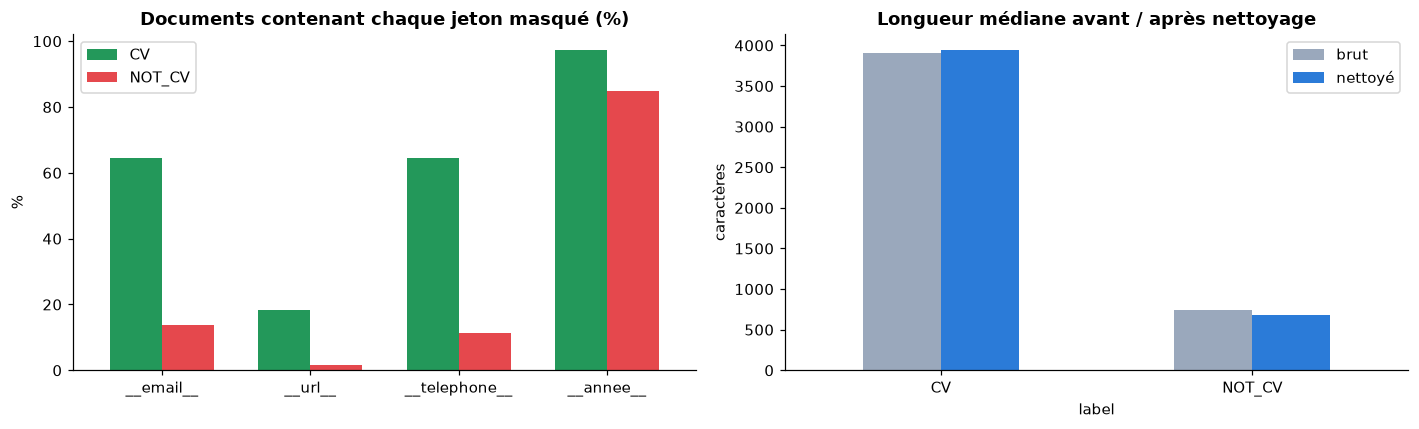

In [17]:
jetons = ["__email__", "__url__", "__telephone__", "__annee__"]
presence = pd.DataFrame({j: df[COLONNE].str.contains(j, regex=False) for j in jetons})
presence["label"] = df["label"]
part = presence.groupby("label")[jetons].mean().T * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
part.plot.bar(ax=axes[0], color=[C_CV, C_NON], rot=0, width=.7)
axes[0].set_title("Documents contenant chaque jeton masqué (%)"); axes[0].set_ylabel("%"); axes[0].legend(title="")

longueurs = pd.DataFrame({"brut": df["texte"].str.len(), "nettoyé": df[COLONNE].str.len(), "label": df["label"]})
longueurs.groupby("label")[["brut", "nettoyé"]].median().plot.bar(ax=axes[1], color=["#9AA8BC", "#2B7BD8"], rot=0)
axes[1].set_title("Longueur médiane avant / après nettoyage"); axes[1].set_ylabel("caractères")
plt.tight_layout(); plt.show()

## 3. Découpage 80 % / 20 % stratifié par classe **et** par langue

Même graine que `train.py` : le jeu de test est exactement celui du modèle en production.

In [18]:
strates = df["label"] + "_" + df["langue"]
entr, test = train_test_split(df, test_size=0.20, stratify=strates, random_state=GRAINE)
entr, test = entr.reset_index(drop=True), test.reset_index(drop=True)
y_entr = (entr["label"] == "CV").astype(int).to_numpy()
y_test = (test["label"] == "CV").astype(int).to_numpy()

pd.DataFrame({
    "entraînement": (entr["label"] + "_" + entr["langue"]).value_counts(),
    "test": (test["label"] + "_" + test["langue"]).value_counts(),
}).fillna(0).astype(int).sort_index()

,entraînement,test
CV_en,29,7
CV_fr,59,15
NOT_CV_en,48,12
NOT_CV_fr,57,15


## 4. Vectorisation TF-IDF (mots et paires de mots)

`ngram_range=(1, 2)`, `min_df=2` (un terme vu dans un seul document — souvent un nom propre — est
écarté), `max_df=0.95`, `sublinear_tf=True`. Le vocabulaire est appris **sur l'entraînement seul**.

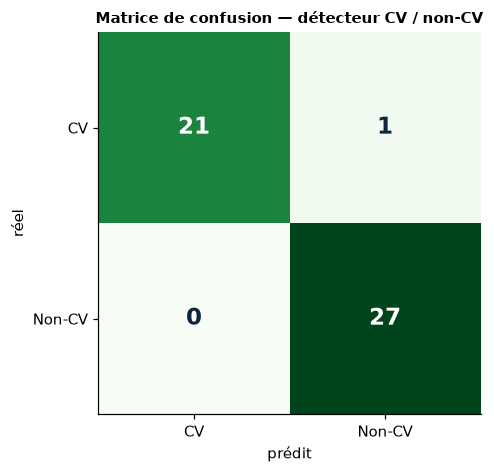

In [48]:
fig, ax = plt.subplots(figsize=(5, 4.4))
tracer_matrice(ax, y_test, p_prod, "Matrice de confusion — détecteur CV / non-CV")
plt.tight_layout(); plt.savefig("figure19_matrice_confusion.png", dpi=200); plt.show()



In [19]:
vect_demo = train._vectoriseur().fit(entr[COLONNE])
termes = vect_demo.get_feature_names_out()
X_demo = vect_demo.transform(entr[COLONNE])
nb_paires = int(sum(" " in t for t in termes))
print(f"vocabulaire          : {len(termes)} termes")
print(f"  mots seuls         : {len(termes) - nb_paires}")
print(f"  paires de mots     : {nb_paires}")
print(f"matrice X (entr.)    : {X_demo.shape[0]} documents × {X_demo.shape[1]} termes")
print(f"valeurs non nulles   : {X_demo.nnz / np.prod(X_demo.shape):.2%}")

vocabulaire          : 8663 termes
  mots seuls         : 3647
  paires de mots     : 5016
matrice X (entr.)    : 193 documents × 8663 termes
valeurs non nulles   : 2.60%


## 5. Pondération classe × langue et augmentation par extraits courts

* **Augmentation** : chaque CV d'entraînement reçoit 4 extraits contigus de 80 à 180 mots (aucun CV
  collecté n'est court).
* **Pondération** : chaque groupe classe × langue pèse autant au total (la plupart des documents
  français sont des non-CV : sans cela, « français » finirait par vouloir dire « pas un CV »).

,documents,poids_unitaire,poids_total
strate,,,
CV_en,145,0.940,136.25
CV_fr,295,0.462,136.25
NOT_CV_en,48,2.839,136.25
NOT_CV_fr,57,2.390,136.25


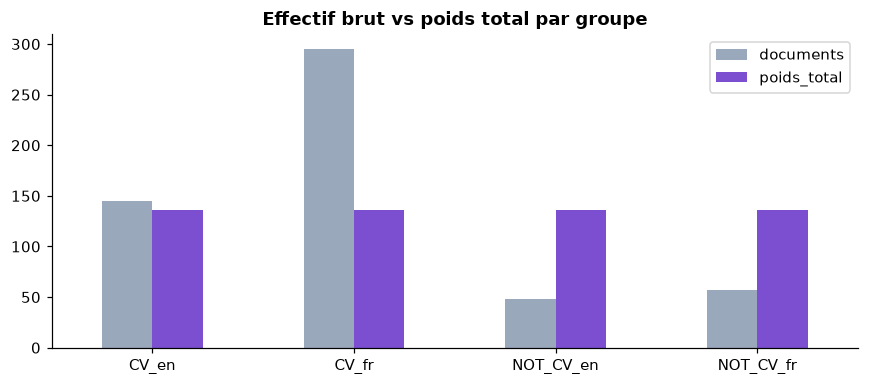

In [20]:
aug_demo = train._augmenter(entr, GRAINE)
poids_demo = train._poids_strates(aug_demo)
tableau = (aug_demo.assign(strate=aug_demo["label"] + "_" + aug_demo["langue"], poids=poids_demo)
           .groupby("strate").agg(documents=("poids", "size"), poids_unitaire=("poids", "first"),
                                  poids_total=("poids", "sum")).round(3))
display(tableau)

fig, ax = plt.subplots(figsize=(8, 3.6))
tableau[["documents", "poids_total"]].plot.bar(ax=ax, color=["#9AA8BC", "#7B4FD0"], rot=0)
ax.set_title("Effectif brut vs poids total par groupe"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Classification : comparaison de 7 algorithmes

Protocole identique pour tous :
1. validation croisée **5 plis stratifiés** sur l'entraînement seul ;
2. dans chaque pli : TF-IDF appris sur le pli, augmentation et pondération sur le pli ;
3. chaque document d'entraînement est prédit une fois, par un modèle qui ne l'a pas vu.

Critère de choix : la **perte logarithmique** (l'API décide sur la *valeur* de la probabilité, avec
deux seuils), puis le F1 de la classe CV en cas d'égalité.

In [47]:
def entrainer(fabrique, originaux, graine=GRAINE, etiquettes_texte=False):
    """TF-IDF sur les originaux, puis modèle sur originaux + extraits, pondéré classe × langue."""
    vect = train._vectoriseur().fit(originaux[COLONNE])
    aug = train._augmenter(originaux, graine)
    X = vect.transform(aug[COLONNE])
    y = aug["label"].to_numpy() if etiquettes_texte else (aug["label"] == "CV").astype(int).to_numpy()
    modele = fabrique()
    try:
        modele.fit(X, y, sample_weight=train._poids_strates(aug))
    except TypeError:                      # k-NN : pas de pondération possible
        modele.fit(X, y)
    return vect, modele


def proba_cv(vect, modele, textes):
    classes = list(modele.classes_)
    indice = classes.index("CV") if "CV" in classes else classes.index(1)
    return modele.predict_proba(vect.transform(textes))[:, indice]


def hors_pli(fabrique, originaux, k=5):
    strates_o = originaux["label"] + "_" + originaux["langue"]
    p = np.zeros(len(originaux))
    plis = StratifiedKFold(k, shuffle=True, random_state=GRAINE)
    for rang, (i_e, i_v) in enumerate(plis.split(originaux, strates_o)):
        vect, modele = entrainer(fabrique, originaux.iloc[i_e].reset_index(drop=True), GRAINE + rang)
        p[i_v] = proba_cv(vect, modele, originaux.iloc[i_v][COLONNE])
    return p


def mesurer(y, p, seuil=0.5):
    y_pred = (p >= seuil).astype(int)
    return {
        "accuracy": accuracy_score(y, y_pred),
        "précision": precision_score(y, y_pred, zero_division=0),
        "rappel": recall_score(y, y_pred, zero_division=0),
        "F1 (CV)": f1_score(y, y_pred, zero_division=0),
        "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
        "ROC AUC": roc_auc_score(y, p),
    }


def tracer_matrice(ax, y, p, titre, seuil=0.5):
    m = confusion_matrix(y, (p >= seuil).astype(int), labels=[1, 0])
    ax.imshow(m, cmap="Greens", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=15, fontweight="bold",
                    color="white" if m[i, j] > m.max() / 2 else C_ENCRE)
    ax.set_xticks([0, 1], ["CV", "Non-CV"]); ax.set_yticks([0, 1], ["CV", "Non-CV"])
    ax.set_xlabel("prédit"); ax.set_ylabel("réel"); ax.set_title(titre, fontsize=10)

### 6.1 Régularisation de la régression logistique (choix de C)

Comme `train.py` : C est choisi sur la perte logarithmique hors pli, entraînement seul.

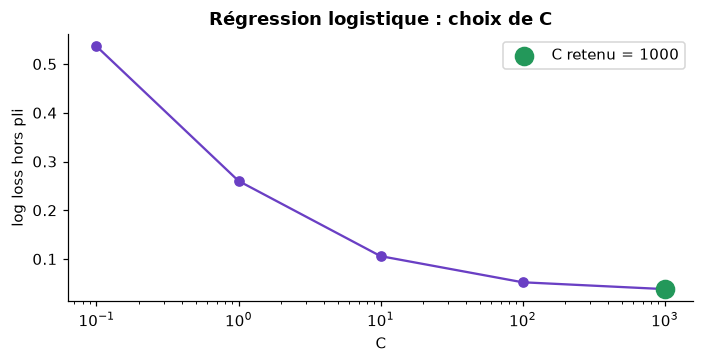

In [46]:
pertes_c = {}
for c in train.VALEURS_C:
    p = hors_pli(lambda: LogisticRegression(C=c, max_iter=5000), entr)
    pertes_c[c] = mesurer(y_entr, p)["log loss"]
C_LR = min(pertes_c, key=pertes_c.get)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(list(pertes_c), list(pertes_c.values()), marker="o", color="#6A3FC4")
ax.scatter([C_LR], [pertes_c[C_LR]], s=140, color=C_CV, zorder=3, label=f"C retenu = {C_LR:g}")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("log loss hors pli")
ax.set_title("Régression logistique : choix de C"); ax.legend()
plt.tight_layout(); plt.show()

### 6.2 Les 7 classifieurs

In [24]:
MODELES = {
    "Régression logistique": lambda: LogisticRegression(C=C_LR, max_iter=5000),
    "Naive Bayes": lambda: MultinomialNB(alpha=0.1),
    "SVM linéaire": lambda: SVC(kernel="linear", probability=True, random_state=GRAINE),
    "k plus proches voisins": lambda: KNeighborsClassifier(n_neighbors=5, metric="cosine", weights="distance"),
    "Arbre de décision": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=2, random_state=GRAINE),
    "Forêt aléatoire": lambda: RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=GRAINE),
}
if XGB:
    MODELES["XGBoost"] = lambda: XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.9, colsample_bytree=0.5,
        eval_metric="logloss", importance_type="gain", random_state=GRAINE, n_jobs=-1)

probas_oof, lignes = {}, []
for nom, fabrique in MODELES.items():
    debut = time.perf_counter()
    probas_oof[nom] = hors_pli(fabrique, entr)
    lignes.append({"modèle": nom, **mesurer(y_entr, probas_oof[nom]),
                   "durée (s)": time.perf_counter() - debut})
    print(f"{nom:24} terminé")

resultats = (pd.DataFrame(lignes).set_index("modèle")
             .sort_values(["log loss", "F1 (CV)"], ascending=[True, False]))
resultats.round(3)

Régression logistique    terminé
Naive Bayes              terminé
SVM linéaire             terminé
k plus proches voisins   terminé
Arbre de décision        terminé
Forêt aléatoire          terminé
XGBoost                  terminé


,accuracy,précision,rappel,F1 (CV),log loss,ROC AUC,durée (s)
modèle,,,,,,,
SVM linéaire,0.995,1.000,0.989,0.994,0.022,1.000,23.887
Régression logistique,0.990,0.989,0.989,0.989,0.038,0.999,20.772
Naive Bayes,0.990,1.000,0.977,0.989,0.058,0.997,23.746
k plus proches voisins,0.964,0.926,1.000,0.962,0.084,1.000,20.109
XGBoost,0.922,0.861,0.989,0.921,0.154,0.994,50.849
Forêt aléatoire,0.974,0.966,0.977,0.972,0.156,0.996,29.285
Arbre de décision,0.886,0.830,0.943,0.883,1.441,0.885,19.999


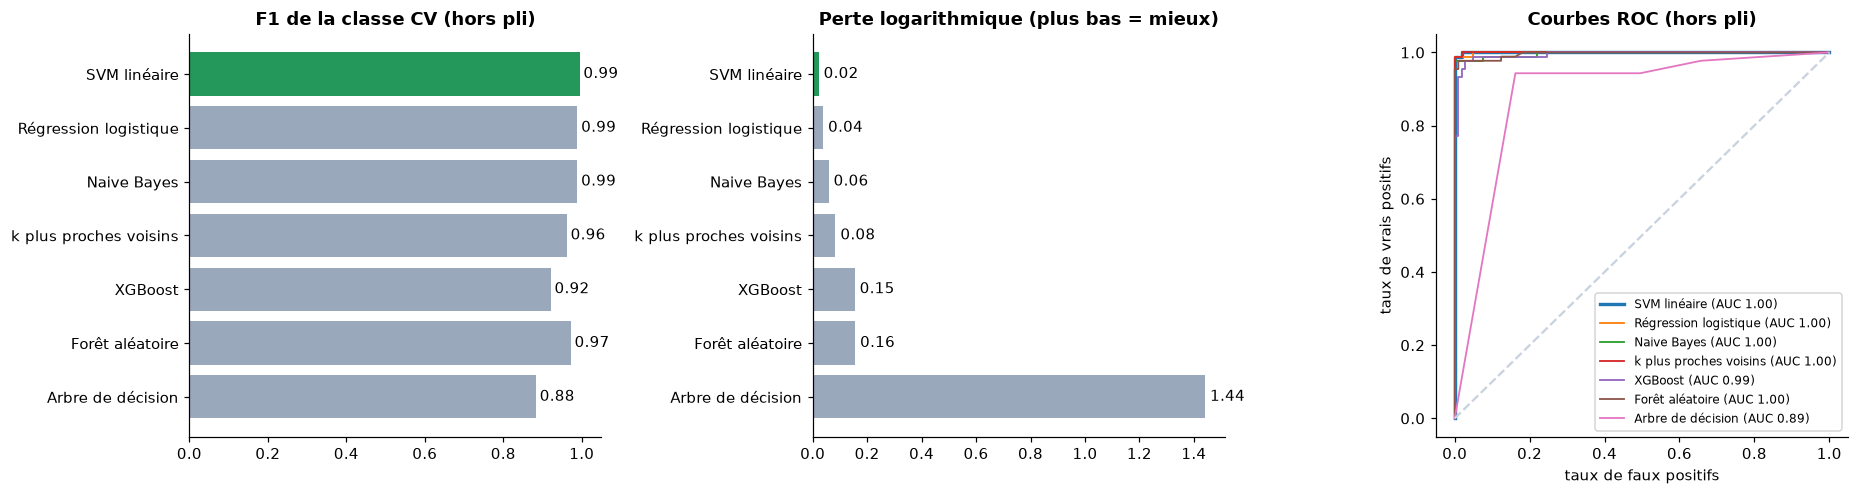

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ordre = resultats.index[::-1]
couleurs = [C_CV if n == resultats.index[0] else "#9AA8BC" for n in ordre]

axes[0].barh(ordre, resultats.loc[ordre, "F1 (CV)"], color=couleurs)
axes[0].set_xlim(0, 1.05); axes[0].set_title("F1 de la classe CV (hors pli)")
for i, v in enumerate(resultats.loc[ordre, "F1 (CV)"]):
    axes[0].text(v + .01, i, f"{v:.2f}", va="center")

axes[1].barh(ordre, resultats.loc[ordre, "log loss"], color=couleurs)
axes[1].set_title("Perte logarithmique (plus bas = mieux)")
for i, v in enumerate(resultats.loc[ordre, "log loss"]):
    axes[1].text(v, i, f" {v:.2f}", va="center")

for nom in resultats.index:
    fpr, tpr, _ = roc_curve(y_entr, probas_oof[nom])
    axes[2].plot(fpr, tpr, lw=2.2 if nom == resultats.index[0] else 1.2,
                 label=f"{nom} (AUC {resultats.loc[nom, 'ROC AUC']:.2f})")
axes[2].plot([0, 1], [0, 1], ls="--", color="#C9D3DF")
axes[2].set_xlabel("taux de faux positifs"); axes[2].set_ylabel("taux de vrais positifs")
axes[2].set_title("Courbes ROC (hors pli)"); axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

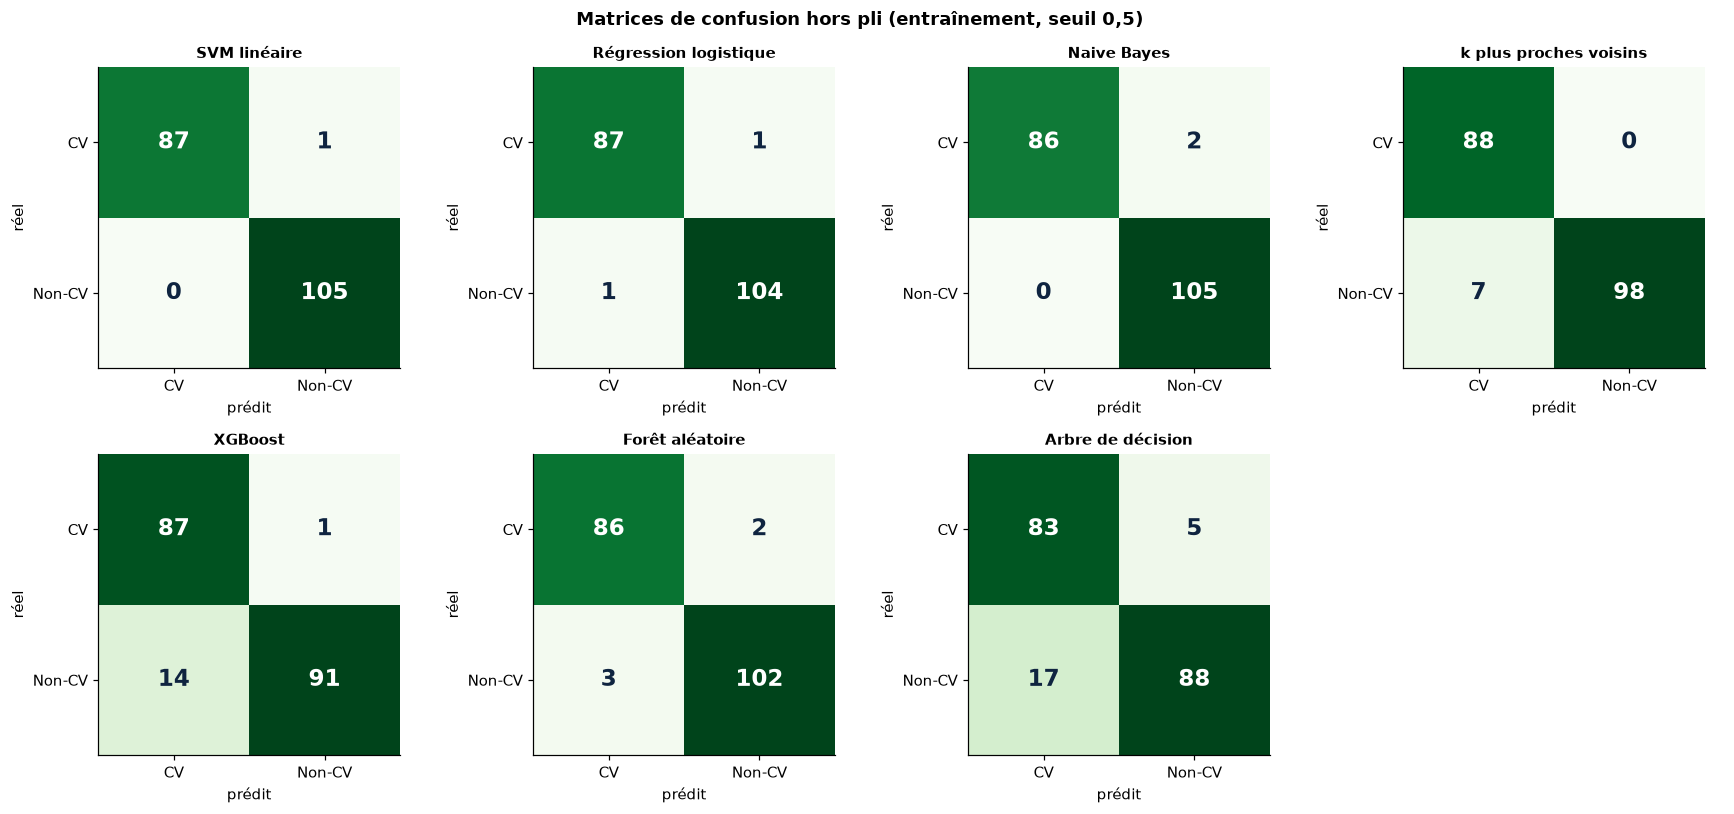

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, nom in zip(axes.flat, resultats.index):
    tracer_matrice(ax, y_entr, probas_oof[nom], nom)
for ax in list(axes.flat)[len(resultats):]:
    ax.axis("off")
fig.suptitle("Matrices de confusion hors pli (entraînement, seuil 0,5)", fontweight="bold")
plt.tight_layout(); plt.show()

## 7. XGBoost en détail

* **Courbe d'apprentissage** : perte logarithmique à chaque arbre ajouté, sur une partie de
  l'entraînement et sur une validation interne (le test reste intact).
* **Importance des termes** (gain moyen apporté par les découpages sur ce terme).

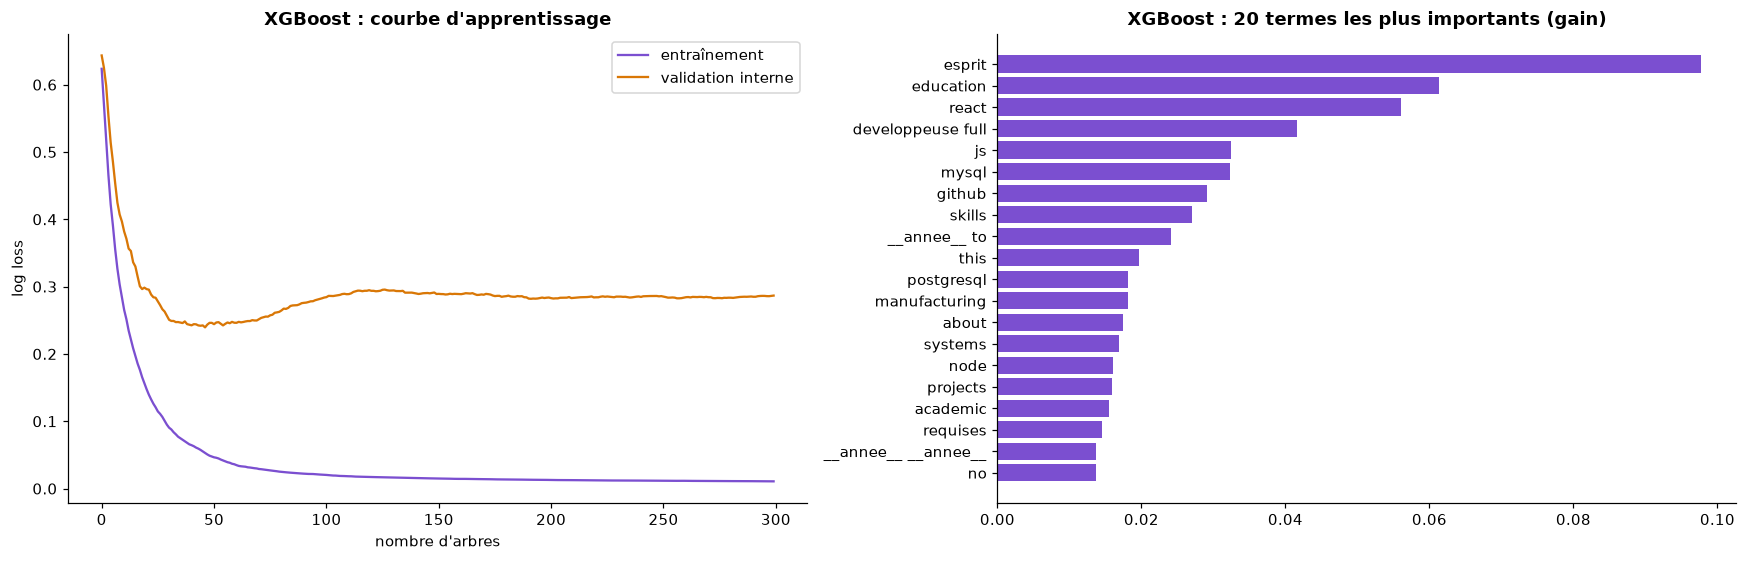

In [28]:
if not XGB:
    print("XGBoost absent : section ignorée.")
else:
    strates_e = entr["label"] + "_" + entr["langue"]
    sous_entr, valid = train_test_split(entr, test_size=0.25, stratify=strates_e, random_state=GRAINE)
    sous_entr, valid = sous_entr.reset_index(drop=True), valid.reset_index(drop=True)
    vect_x = train._vectoriseur().fit(sous_entr[COLONNE])
    aug_x = train._augmenter(sous_entr, GRAINE)
    X_tr, y_tr = vect_x.transform(aug_x[COLONNE]), (aug_x["label"] == "CV").astype(int)
    X_va, y_va = vect_x.transform(valid[COLONNE]), (valid["label"] == "CV").astype(int)
    xgb_courbe = MODELES["XGBoost"]()
    xgb_courbe.fit(X_tr, y_tr, sample_weight=train._poids_strates(aug_x),
                   eval_set=[(X_tr, y_tr), (X_va, y_va)], verbose=False)
    histo = xgb_courbe.evals_result()

    vect_xgb, modele_xgb = entrainer(MODELES["XGBoost"], entr)
    importance = (pd.Series(modele_xgb.feature_importances_, index=vect_xgb.get_feature_names_out())
                  .nlargest(20).sort_values())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
    axes[0].plot(histo["validation_0"]["logloss"], label="entraînement", color="#7B4FD0")
    axes[0].plot(histo["validation_1"]["logloss"], label="validation interne", color="#D97706")
    axes[0].set_xlabel("nombre d'arbres"); axes[0].set_ylabel("log loss")
    axes[0].set_title("XGBoost : courbe d'apprentissage"); axes[0].legend()
    axes[1].barh(importance.index, importance.values, color="#7B4FD0")
    axes[1].set_title("XGBoost : 20 termes les plus importants (gain)")
    plt.tight_layout(); plt.show()

Pour comparaison, les termes qui pèsent le plus dans la **régression logistique** (coefficients) —
vers « CV » (vert) et vers « non-CV » (rouge) :

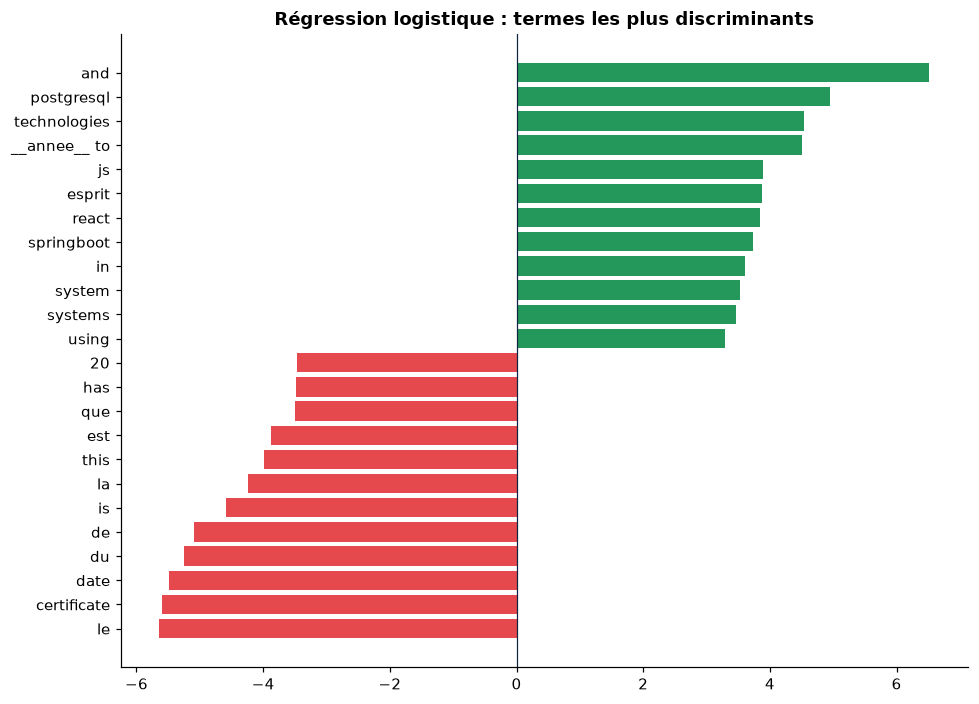

In [32]:
vect_lr, modele_lr = entrainer(MODELES["Régression logistique"], entr)
coef = pd.Series(modele_lr.coef_[0], index=vect_lr.get_feature_names_out())
extremes = pd.concat([coef.nsmallest(12), coef.nlargest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(extremes.index, extremes.values, color=[C_CV if v > 0 else C_NON for v in extremes.values])
ax.axvline(0, color=C_ENCRE, lw=.8)
ax.set_title("Régression logistique : termes les plus discriminants")
plt.tight_layout(); plt.show()

## 8. Arbre de décision

Un arbre de profondeur 3, entraîné sur tout l'entraînement, pour **lire** les règles qu'il apprend
(chaque nœud teste le poids TF-IDF d'un terme).

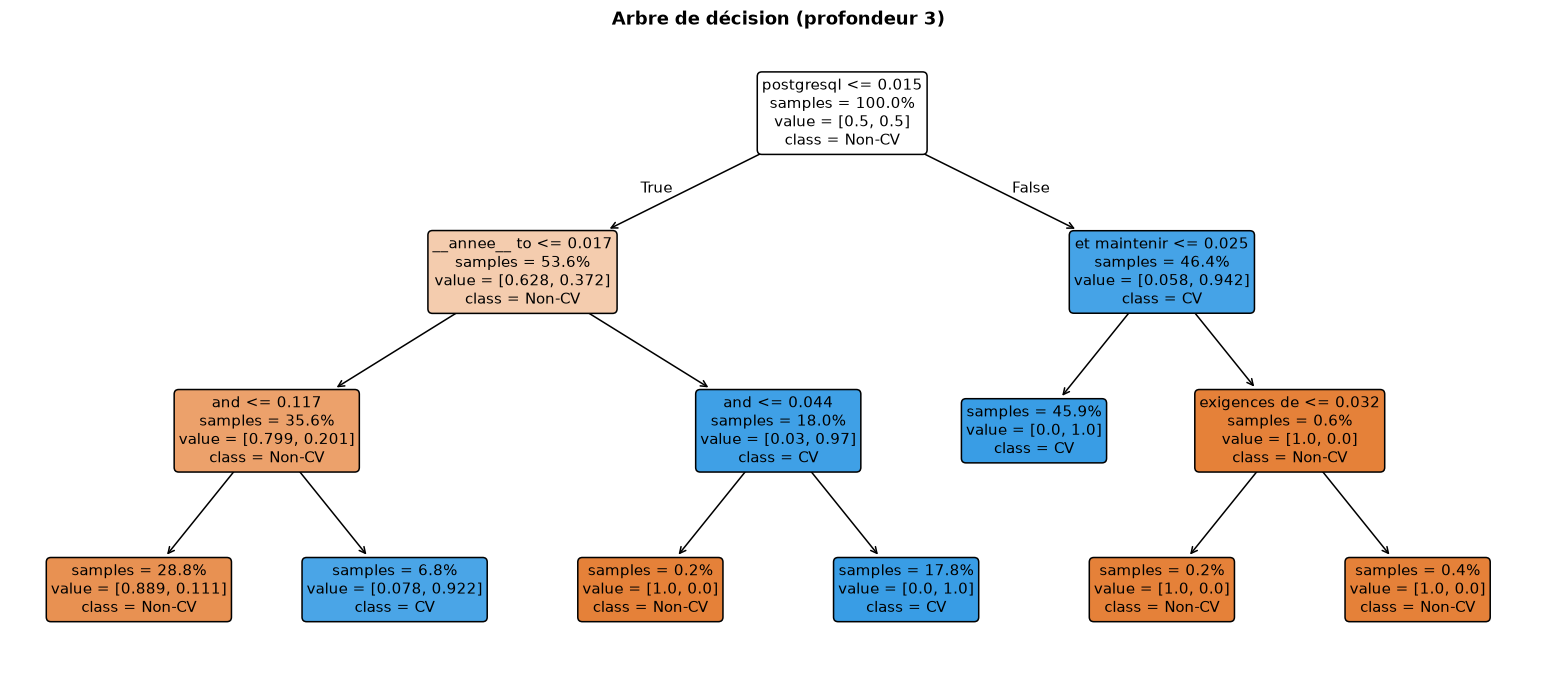

|--- postgresql <= 0.02
|   |--- __annee__ to <= 0.02
|   |   |--- and <= 0.12
|   |   |   |--- class: 0
|   |   |--- and >  0.12
|   |   |   |--- class: 1
|   |--- __annee__ to >  0.02
|   |   |--- and <= 0.04
|   |   |   |--- class: 0
|   |   |--- and >  0.04
|   |   |   |--- class: 1
|--- postgresql >  0.02
|   |--- et maintenir <= 0.03
|   |   |--- class: 1
|   |--- et maintenir >  0.03
|   |   |--- exigences de <= 0.03
|   |   |   |--- class: 0
|   |   |--- exigences de >  0.03
|   |   |   |--- class: 0



In [33]:
vect_arbre, arbre = entrainer(lambda: DecisionTreeClassifier(max_depth=3, random_state=GRAINE), entr)
fig, ax = plt.subplots(figsize=(18, 7.5))
plot_tree(arbre, feature_names=vect_arbre.get_feature_names_out(), class_names=["Non-CV", "CV"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
ax.set_title("Arbre de décision (profondeur 3)")
plt.show()
print(export_text(arbre, feature_names=list(vect_arbre.get_feature_names_out())))

## 9. Clustering K-Means (non supervisé)

Question : sans connaître les étiquettes, les documents se regroupent-ils naturellement en CV /
non-CV ? TF-IDF → réduction à 50 dimensions (SVD) → normalisation → K-Means pour k = 2 à 8.

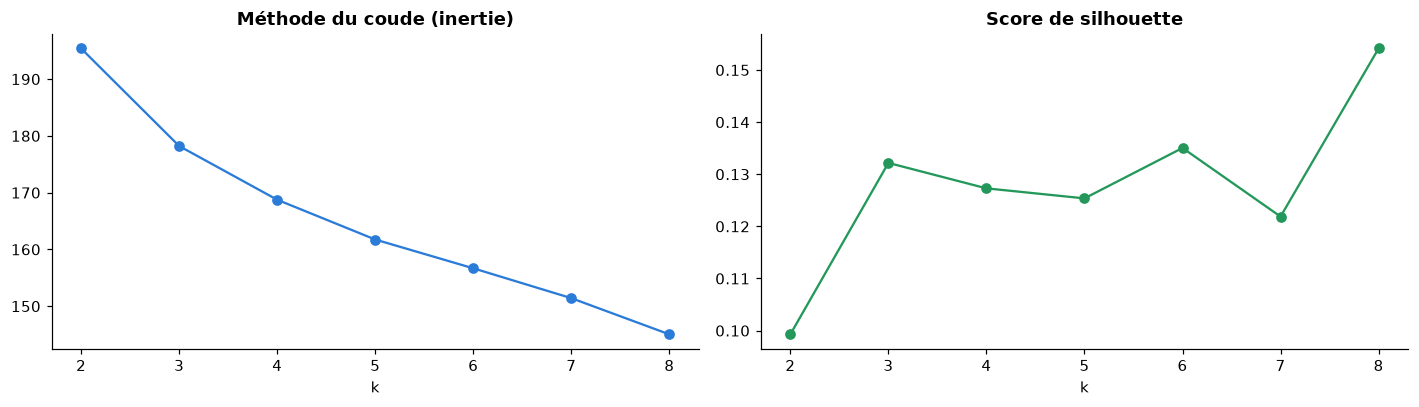

k au meilleur score de silhouette : 8


In [34]:
vect_k = train._vectoriseur().fit(df[COLONNE])
X_k = vect_k.transform(df[COLONNE])
Z = Normalizer().fit_transform(TruncatedSVD(n_components=50, random_state=GRAINE).fit_transform(X_k))

ks = list(range(2, 9))
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=GRAINE).fit(Z)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(ks, inerties, marker="o", color="#2B7BD8"); axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("k")
axes[1].plot(ks, silhouettes, marker="o", color="#23985A"); axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(f"k au meilleur score de silhouette : {ks[int(np.argmax(silhouettes))]}")

cluster         0   1
label  langue        
CV     en       0  36
       fr      71   3
NOT_CV en       0  60
       fr      72   0

indice de Rand ajusté (cluster vs classe) : 0.00
indice de Rand ajusté (cluster vs langue) : 0.95
homogénéité vis-à-vis de la classe        : 0.01


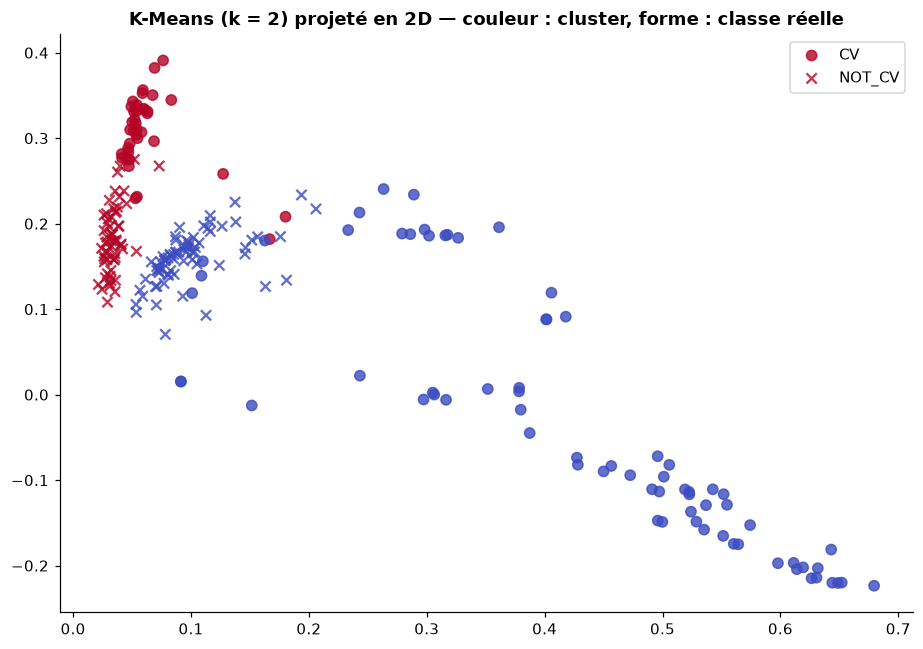

In [35]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=GRAINE).fit(Z)
clusters = df[["label", "langue"]].assign(cluster=km2.labels_)
display(pd.crosstab([clusters["label"], clusters["langue"]], clusters["cluster"]))
print(f"indice de Rand ajusté (cluster vs classe) : {adjusted_rand_score(df['label'], km2.labels_):.2f}")
print(f"indice de Rand ajusté (cluster vs langue) : {adjusted_rand_score(df['langue'], km2.labels_):.2f}")
print(f"homogénéité vis-à-vis de la classe        : {homogeneity_score(df['label'], km2.labels_):.2f}")

plan = TruncatedSVD(n_components=2, random_state=GRAINE).fit_transform(X_k)
fig, ax = plt.subplots(figsize=(8.5, 6))
for label, marqueur in (("CV", "o"), ("NOT_CV", "x")):
    masque = (df["label"] == label).to_numpy()
    ax.scatter(plan[masque, 0], plan[masque, 1], c=km2.labels_[masque], cmap="coolwarm",
               marker=marqueur, s=45, alpha=.8, label=label)
ax.set_title("K-Means (k = 2) projeté en 2D — couleur : cluster, forme : classe réelle")
ax.legend(); plt.tight_layout(); plt.show()

**Lecture** — un indice de Rand proche de 1 signifierait que les clusters retrouvent les classes ;
proche de 0, qu'ils suivent autre chose (souvent la **langue** ou le type de document). C'est ce qui
justifie un modèle **supervisé** pour la détection de CV.

## 10. Régression : prédiction du salaire

Le détecteur de CV est un problème de **classification** (sa « régression logistique » est un
classifieur). La régression au sens propre — prédire une valeur continue — est l'autre modèle de
PIQBIT : le **salaire mensuel brut (TND)**, à partir de `datasets/tunisia_it_salaries.csv`.

Validation croisée **groupée par intitulé de poste** (`GroupKFold`) : un même poste n'est jamais à
la fois en entraînement et en validation, sinon le modèle « reconnaîtrait » le poste au lieu
d'apprendre. Le pipeline de production (`scripts/salary_ml_pipeline.py`) est plus complet ; ce
paragraphe compare les familles d'algorithmes dans un cadre simple et identique pour tous.

In [36]:
sal = pd.read_csv(BACKEND / "datasets" / "tunisia_it_salaries.csv").dropna(subset=["salary_avg_tnd"])
CAT = ["category", "seniority", "education"]
NUM = ["experience_years_min", "experience_years_max", "nb_competences"]
sal[CAT] = sal[CAT].fillna("inconnu")
competences = sal["top_skills"].fillna("")
sal["nb_competences"] = competences.str.count(",") + (competences != "").astype(int)
X_s, y_s, groupes = sal[CAT + NUM], sal["salary_avg_tnd"].astype(float), sal["title"]

preparation = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ("num", SimpleImputer(strategy="median"), NUM),
])
REGRESSEURS = {
    "Régression linéaire": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "k plus proches voisins": KNeighborsRegressor(n_neighbors=5),
    "Arbre de décision": DecisionTreeRegressor(max_depth=6, random_state=GRAINE),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=400, random_state=GRAINE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=GRAINE),
}
if XGB:
    REGRESSEURS["XGBoost"] = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                                          subsample=0.9, random_state=GRAINE, n_jobs=-1)

plis_g = GroupKFold(n_splits=5)
lignes_r = []
for nom, regresseur in REGRESSEURS.items():
    scores = cross_validate(make_pipeline(preparation, regresseur), X_s, y_s, groups=groupes, cv=plis_g,
                            scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error",
                                     "R2": "r2"})
    lignes_r.append({"modèle": nom, "MAE (TND)": -scores["test_MAE"].mean(),
                     "RMSE (TND)": -scores["test_RMSE"].mean(), "R²": scores["test_R2"].mean()})
resultats_r = pd.DataFrame(lignes_r).set_index("modèle").sort_values("MAE (TND)")
MEILLEUR_REG = resultats_r.index[0]
resultats_r.round({"MAE (TND)": 0, "RMSE (TND)": 0, "R²": 3})

,MAE (TND),RMSE (TND),R²
modèle,,,
XGBoost,701.0,987.0,0.703
Forêt aléatoire,713.0,988.0,0.705
Arbre de décision,717.0,1054.0,0.666
Gradient Boosting,724.0,1032.0,0.679
k plus proches voisins,751.0,1092.0,0.636
Ridge,789.0,1070.0,0.654
Régression linéaire,841.0,1127.0,0.614


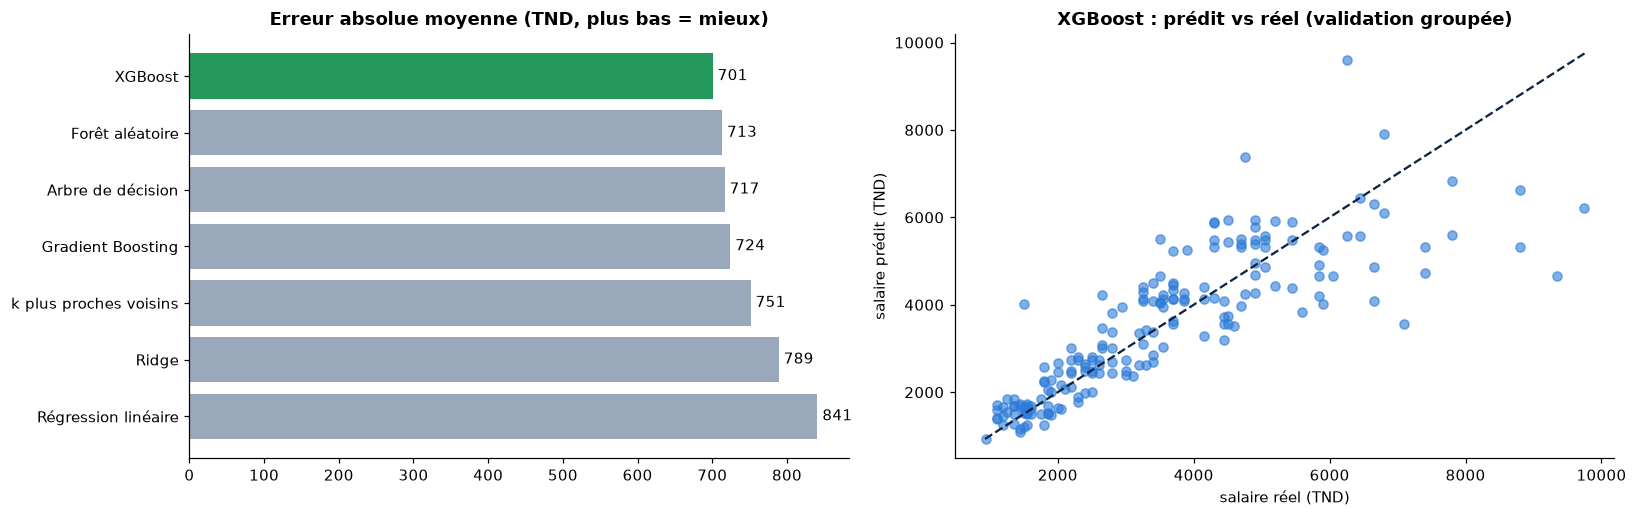

In [37]:
pred_s = cross_val_predict(make_pipeline(preparation, REGRESSEURS[MEILLEUR_REG]), X_s, y_s,
                           groups=groupes, cv=plis_g)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ordre_r = resultats_r.index[::-1]
axes[0].barh(ordre_r, resultats_r.loc[ordre_r, "MAE (TND)"],
             color=[C_CV if n == MEILLEUR_REG else "#9AA8BC" for n in ordre_r])
axes[0].set_title("Erreur absolue moyenne (TND, plus bas = mieux)")
for i, v in enumerate(resultats_r.loc[ordre_r, "MAE (TND)"]):
    axes[0].text(v, i, f" {v:.0f}", va="center")
axes[1].scatter(y_s, pred_s, alpha=.6, color="#2B7BD8")
borne = [min(y_s.min(), pred_s.min()), max(y_s.max(), pred_s.max())]
axes[1].plot(borne, borne, ls="--", color=C_ENCRE)
axes[1].set_xlabel("salaire réel (TND)"); axes[1].set_ylabel("salaire prédit (TND)")
axes[1].set_title(f"{MEILLEUR_REG} : prédit vs réel (validation groupée)")
plt.tight_layout(); plt.show()

## 11. Choix du meilleur classifieur et évaluation sur le jeu de test

Le meilleur classifieur du § 6 (plus faible perte logarithmique) est réentraîné sur **tout**
l'entraînement, puis évalué **une seule fois** sur les 20 % de test — jamais vus jusqu'ici. Il est
comparé au modèle actuellement en production (`models/`).

In [49]:
MEILLEUR = resultats.index[0]
print(f"Meilleur classifieur (validation croisée) : {MEILLEUR}")

vect_best, modele_best = entrainer(MODELES[MEILLEUR], entr)
p_test = proba_cv(vect_best, modele_best, test[COLONNE])

comparaison = {f"{MEILLEUR} (notebook)": mesurer(y_test, p_test)}
p_prod = None
if (DOSSIER_MODELES / DetecteurCV.FICHIER_MODELE).exists():
    modele_prod = joblib.load(DOSSIER_MODELES / DetecteurCV.FICHIER_MODELE)
    vect_prod = joblib.load(DOSSIER_MODELES / DetecteurCV.FICHIER_VECTORISEUR)
    p_prod = proba_cv(vect_prod, modele_prod, test[COLONNE])
    comparaison["modèle en production"] = mesurer(y_test, p_prod)
pd.DataFrame(comparaison).T.round(3)

Meilleur classifieur (validation croisée) : SVM linéaire


,accuracy,précision,rappel,F1 (CV),log loss,ROC AUC
SVM linéaire (notebook),0.98,1.0,0.955,0.977,0.057,1.0
modèle en production,0.98,1.0,0.955,0.977,0.049,1.0


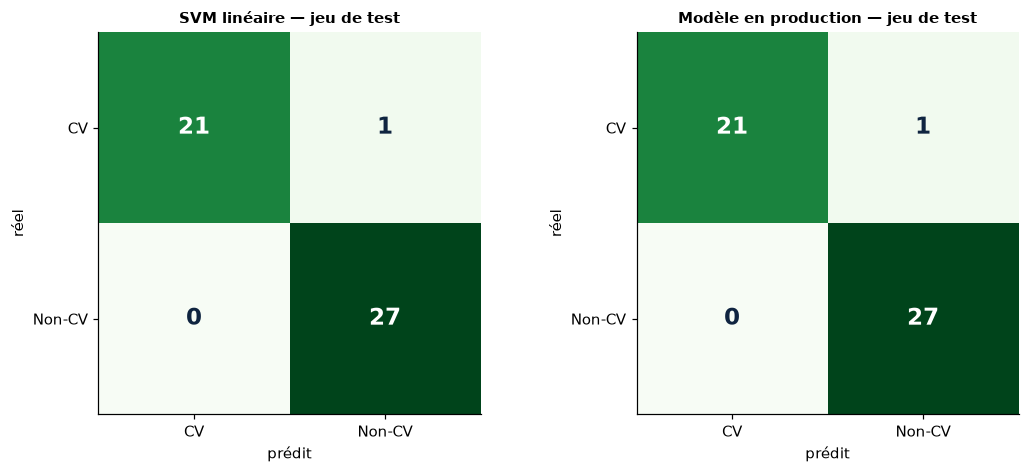

In [39]:
fig, axes = plt.subplots(1, 2 if p_prod is not None else 1, figsize=(10, 4.4), squeeze=False)
tracer_matrice(axes[0, 0], y_test, p_test, f"{MEILLEUR} — jeu de test")
if p_prod is not None:
    tracer_matrice(axes[0, 1], y_test, p_prod, "Modèle en production — jeu de test")
plt.tight_layout(); plt.show()

## 12. Seuils de décision et tests de résistance

L'API ne coupe pas à 0,5 : elle **refuse** sous le seuil bas, **accepte** au-dessus du seuil haut,
et accepte avec réserve entre les deux (zone incertaine).

col_0,refusé,incertain,accepté
label,,,
CV,1,0,21
NOT_CV,27,0,0


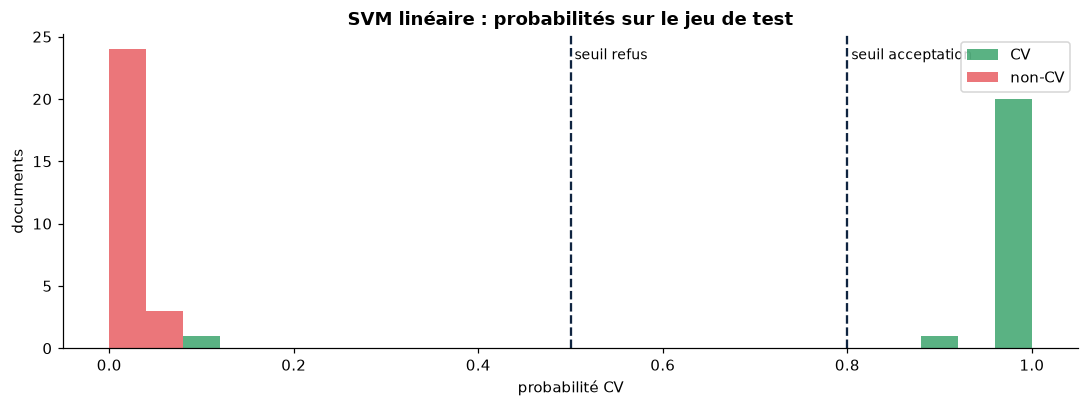

In [40]:
def zone(p):
    return np.where(p >= SEUIL_ACCEPTE, "accepté", np.where(p < SEUIL_REFUS, "refusé", "incertain"))

display(pd.crosstab(test["label"], zone(p_test)).reindex(columns=["refusé", "incertain", "accepté"], fill_value=0))

fig, ax = plt.subplots(figsize=(10, 3.8))
bornes_p = np.linspace(0, 1, 26)
ax.hist(p_test[y_test == 1], bins=bornes_p, alpha=.75, color=C_CV, label="CV")
ax.hist(p_test[y_test == 0], bins=bornes_p, alpha=.75, color=C_NON, label="non-CV")
for s, nom in ((SEUIL_REFUS, "refus"), (SEUIL_ACCEPTE, "acceptation")):
    ax.axvline(s, color=C_ENCRE, ls="--"); ax.text(s, ax.get_ylim()[1] * .92, f" seuil {nom}", fontsize=9)
ax.set_xlabel("probabilité CV"); ax.set_ylabel("documents")
ax.set_title(f"{MEILLEUR} : probabilités sur le jeu de test"); ax.legend()
plt.tight_layout(); plt.show()

In [41]:
# Résistance : un CV tronqué à 800 caractères (la longueur d'un non-CV) est-il encore reconnu ?
cv_test = test[test["label"] == "CV"]
courts = [t[:800] for t in cv_test[COLONNE]]
resistance = {MEILLEUR: proba_cv(vect_best, modele_best, courts)}
if p_prod is not None:
    resistance["modèle en production"] = proba_cv(vect_prod, modele_prod, courts)
pd.DataFrame({nom: {"CV courts reconnus (≥ 0,5)": f"{(p >= .5).sum()} / {len(p)}",
                    "refusés (< seuil bas)": int((p < SEUIL_REFUS).sum()),
                    "probabilité médiane": round(float(np.median(p)), 2)}
              for nom, p in resistance.items()})

,SVM linéaire,modèle en production
"CV courts reconnus (≥ 0,5)",19 / 22,20 / 22
refusés (< seuil bas),3,2
probabilité médiane,0.97,0.99


## 13. Démonstration : refus d'un document non-CV au dépôt

Une facture **fictive** est mise en PDF, relue par l'extracteur de production, puis évaluée — par
le meilleur modèle du notebook et par le détecteur réellement utilisé par l'API.

SVM linéaire (notebook) : probabilité CV 0.01 -> refusé
Détecteur de l'API      : probabilité CV 0.02 -> refuse
Réponse au candidat     : HTTP 400 — ❌ Le document envoyé ne semble pas être un CV. Veuillez importer votre CV.


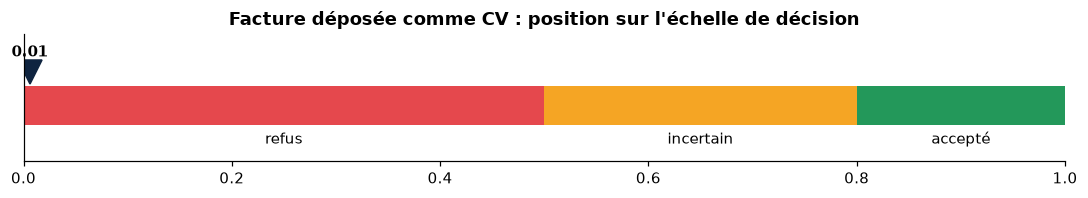

In [42]:
FACTURE = """FACTURE N° 2026-0412
Date d'émission : 12 septembre 2026
Société cliente : Atelier Numérique SARL
Maintenance du parc informatique   1   450,00   450,00
Licence logicielle annuelle        3   120,00   360,00
Total HT : 810,00 TND — TVA 19 % : 153,90 TND — Total TTC : 963,90 TND
Conditions de paiement : virement à 30 jours fin de mois."""


def en_pdf(texte):
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.platypus import Paragraph, SimpleDocTemplate
    tampon = BytesIO()
    style = getSampleStyleSheet()["Normal"]
    SimpleDocTemplate(tampon, pagesize=A4).build(
        [Paragraph(escape(l), style) for l in texte.splitlines() if l.strip()])
    return tampon.getvalue()


texte_extrait = cv_parser.extract_text_from_bytes(en_pdf(FACTURE), ".pdf")
p_facture = float(proba_cv(vect_best, modele_best, [texte_extrait])[0])
verdict = DetecteurCV().evaluer(texte_extrait)

print(f"{MEILLEUR} (notebook) : probabilité CV {p_facture:.2f} -> {zone(np.array([p_facture]))[0]}")
proba_api = "n/a" if verdict.probabilite_cv is None else f"{verdict.probabilite_cv:.2f}"
print(f"Détecteur de l'API      : probabilité CV {proba_api} -> {verdict.decision}")
if verdict.bloquant:
    print(f"Réponse au candidat     : HTTP 400 — {verdict.message}")

fig, ax = plt.subplots(figsize=(10, 1.9))
for a, b, c, nom in ((0, SEUIL_REFUS, C_NON, "refus"), (SEUIL_REFUS, SEUIL_ACCEPTE, "#F5A524", "incertain"),
                     (SEUIL_ACCEPTE, 1, C_CV, "accepté")):
    ax.barh(0, b - a, left=a, color=c, height=.5)
    ax.text((a + b) / 2, -.48, nom, ha="center", fontsize=10)
ax.plot([p_facture], [0.42], marker="v", markersize=16, color=C_ENCRE)
ax.text(p_facture, .62, f"{p_facture:.2f}", ha="center", fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(-.7, .9); ax.set_yticks([])
ax.set_title("Facture déposée comme CV : position sur l'échelle de décision")
plt.tight_layout(); plt.show()

## 14. Appliquer le meilleur modèle

Par sécurité, rien n'est écrit tant que `APPLIQUER = False`. Avec `True`, le meilleur classifieur
est réentraîné sur l'entraînement (étiquettes texte « CV » / « NOT_CV », format attendu par l'API)
puis sauvegardé dans `models/` à la place du modèle actuel.

* XGBoost travaille sur des étiquettes numériques : l'API (`DetecteurCV`) ne saurait pas le
  charger tel quel — il n'est donc pas sauvegardé, même s'il gagne.
* Après la sauvegarde, **redémarrer l'API** pour qu'elle charge le nouveau modèle.

In [43]:
APPLIQUER = False

if not APPLIQUER:
    print(f"Simulation : « {MEILLEUR} » serait appliqué. Passez APPLIQUER = True pour l'écrire dans models/.")
elif MEILLEUR == "XGBoost":
    print("XGBoost n'est pas compatible avec le chargement de l'API : modèle actuel conservé.")
else:
    vect_app, modele_app = entrainer(MODELES[MEILLEUR], entr, etiquettes_texte=True)
    # Comme train.py : `stop_words_` liste les termes vus dans un seul document (noms, villes) — inutile, non sauvegardé.
    vect_app.stop_words_ = None
    joblib.dump(modele_app, DOSSIER_MODELES / DetecteurCV.FICHIER_MODELE, compress=3)
    joblib.dump(vect_app, DOSSIER_MODELES / DetecteurCV.FICHIER_VECTORISEUR, compress=3)

    chemin_meta = DOSSIER_MODELES / DetecteurCV.FICHIER_METADONNEES
    meta = json.loads(chemin_meta.read_text(encoding="utf-8")) if chemin_meta.exists() else {}
    m_test = mesurer(y_test, proba_cv(vect_app, modele_app, test[COLONNE]))
    meta.update({
        "algorithme": f"TF-IDF (mots et paires de mots) + {MEILLEUR}",
        "entraine_le": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "source": "notebook_detecteur_cv.ipynb",
        "test": {"accuracy": round(m_test["accuracy"], 4), "precision_cv": round(m_test["précision"], 4),
                 "recall_cv": round(m_test["rappel"], 4), "f1_cv": round(m_test["F1 (CV)"], 4)},
        "comparaison_validation_croisee": resultats[["log loss", "F1 (CV)"]].round(4).to_dict(orient="index"),
    })
    chemin_meta.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"« {MEILLEUR} » sauvegardé dans {DOSSIER_MODELES}. Redémarrez l'API.")

Simulation : « SVM linéaire » serait appliqué. Passez APPLIQUER = True pour l'écrire dans models/.


## Synthèse

In [44]:
print(f"Classification — meilleur modèle (validation croisée) : {MEILLEUR}")
print(f"   log loss {resultats.loc[MEILLEUR, 'log loss']:.3f} | F1 (CV) {resultats.loc[MEILLEUR, 'F1 (CV)']:.3f}")
m = mesurer(y_test, p_test)
print(f"   jeu de test : accuracy {m['accuracy']:.3f} | précision {m['précision']:.3f} | "
      f"rappel {m['rappel']:.3f} | F1 {m['F1 (CV)']:.3f}")
print(f"Régression (salaire) — meilleur modèle : {MEILLEUR_REG} "
      f"(MAE {resultats_r.loc[MEILLEUR_REG, 'MAE (TND)']:.0f} TND, R² {resultats_r.loc[MEILLEUR_REG, 'R²']:.2f})")
print(f"Clustering K-Means (k = 2) — indice de Rand ajusté avec la classe : "
      f"{adjusted_rand_score(df['label'], km2.labels_):.2f}")

Classification — meilleur modèle (validation croisée) : SVM linéaire
   log loss 0.022 | F1 (CV) 0.994
   jeu de test : accuracy 0.980 | précision 1.000 | rappel 0.955 | F1 0.977
Régression (salaire) — meilleur modèle : XGBoost (MAE 701 TND, R² 0.70)
Clustering K-Means (k = 2) — indice de Rand ajusté avec la classe : 0.00
